# Tox21 SR-ARE: Variational Quantum Classifier (VQC) vs Classical Baselines

Optimised pipeline design for 4 - 6 qubit.

Run the cells **top to bottom**.

**Install once (in a terminal or a notebook cell):**
```
pip install pandas numpy matplotlib seaborn scikit-learn rdkit qiskit qiskit-machine-learning qiskit-algorithms pylatexenc
```

## 1. Setup and configuration

In [ ]:
import time, warnings, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=DeprecationWarning)

# ============================ CONFIG ============================
DATA_PATH         = "tox21.csv"   
TARGET            = "SR-ARE"      # any of the 12 Tox21 endpoints
SEED              = 42
TEST_SIZE         = 0.20

N_QUBITS          = 4             # = number of input features. 4-6
FM_REPS           = 1             # feature-map repetitions (1 = shallow, fast)
ANSATZ_REPS       = 2             # ansatz repetitions -> parameters = N_QUBITS * (ANSATZ_REPS + 1)

N_TRAIN_PER_CLASS = 250           # training samples per class (500 total). Lower = faster
MAXITER           = 300           # COBYLA iterations. Lower = faster


random.seed(SEED); np.random.seed(SEED)
sns.set_theme(style="whitegrid")
print("Config OK | qubits:", N_QUBITS, "| train/class:", N_TRAIN_PER_CLASS, "| maxiter:", MAXITER)

Config OK | qubits: 4 | train/class: 250 | maxiter: 300


## 2. Load data and explore missing values

Molecules: 7831 | Targets: 12


,Missing (%),Active ratio (%),Total valid
NR-AR,7.23,4.25,7265
SR-ATAD5,9.69,3.73,7072
NR-ER-LBD,11.19,5.03,6955
SR-p53,13.50,6.24,6774
NR-AR-LBD,13.70,3.51,6758
NR-AhR,16.37,11.73,6549
SR-HSE,17.42,5.75,6467
NR-PPAR-gamma,17.64,2.88,6450
NR-ER,20.92,12.80,6193
SR-ARE,25.53,16.15,5832


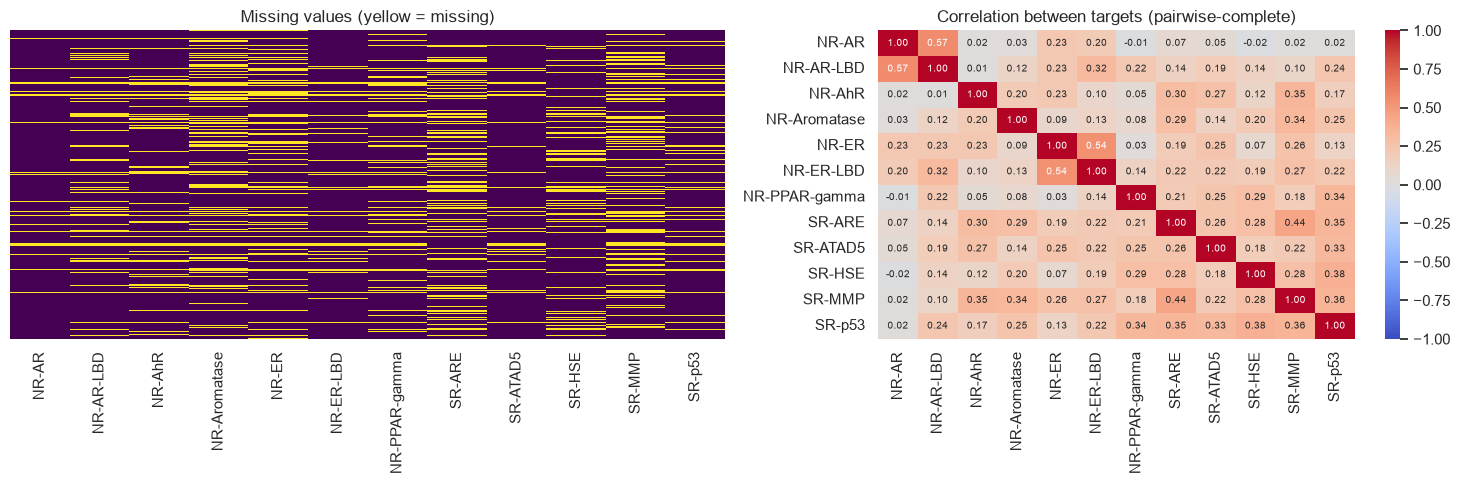

In [ ]:
import os
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"'{DATA_PATH}' not found. Place tox21.csv in the same folder as this notebook.")

df = pd.read_csv(DATA_PATH)
targets = [c for c in df.columns if c not in ("mol_id", "smiles")]  
print("Molecules:", len(df), "| Targets:", len(targets))

summary = pd.DataFrame({
    "Missing (%)":      df[targets].isnull().mean() * 100,
    "Active ratio (%)": df[targets].mean() * 100,      
    "Total valid":      df[targets].count(),
}).sort_values("Missing (%)").round(2)
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.2, 1]})
sns.heatmap(df[targets].isnull(), cbar=False, cmap="viridis", yticklabels=False, ax=axes[0])
axes[0].set_title("Missing values (yellow = missing)")
sns.heatmap(df[targets].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            annot_kws={"size": 7}, ax=axes[1])
axes[1].set_title("Correlation between targets (pairwise-complete)")
plt.tight_layout(); plt.show()

## 3. Clean data and featurise molecules
- Drops rows with no label, invalid SMILES, and duplicate SMILES (duplicates could leak across train/test)
- Computes two feature sets: **Morgan fingerprints** (2048 bits) and **RDKit physico-chemical descriptors**

In [ ]:
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, rdFingerprintGenerator
RDLogger.DisableLog("rdApp.*")          

d = df[["smiles", TARGET]].dropna().drop_duplicates(subset="smiles").reset_index(drop=True)
d["mol"] = d["smiles"].apply(Chem.MolFromSmiles)
n_bad = d["mol"].isnull().sum()
d = d[d["mol"].notnull()].reset_index(drop=True)
print(f"Removed {n_bad} invalid SMILES | usable molecules: {len(d)}")

fp_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
DESC_NAMES = ["MolWt", "MolLogP", "MolMR", "TPSA", "LabuteASA", "NumHDonors", "NumHAcceptors",
              "NumRotatableBonds", "RingCount", "NumAromaticRings", "NumAliphaticRings",
              "FractionCSP3", "HeavyAtomCount", "NumHeteroatoms", "BertzCT", "BalabanJ",
              "Chi0v", "Kappa2", "HallKierAlpha", "qed", "fr_halogen", "fr_phenol", "fr_benzene"]
desc_funcs = [getattr(Descriptors, n) for n in DESC_NAMES]

def safe_desc(m):
    out = []
    for f in desc_funcs:
        try: out.append(float(f(m)))
        except Exception: out.append(np.nan)
    return out

t0 = time.time()
X_fp   = np.vstack([fp_gen.GetFingerprintAsNumPy(m) for m in d["mol"]]).astype(np.uint8)
X_desc = np.array([safe_desc(m) for m in d["mol"]], dtype=np.float64)
X_desc[~np.isfinite(X_desc)] = np.nan
y_all  = d[TARGET].astype(int).values
print(f"Fingerprints {X_fp.shape} | Descriptors {X_desc.shape} | featurised in {time.time()-t0:.1f}s")
print("Class balance (natural): inactive =", (y_all == 0).sum(), "| active =", (y_all == 1).sum(),
      f"({y_all.mean()*100:.1f}% active)")

Removed 7 invalid SMILES | usable molecules: 5825
Fingerprints (5825, 2048) | Descriptors (5825, 23) | featurised in 15.5s
Class balance (natural): inactive = 4883 | active = 942 (16.2% active)


## 4. Split first (stratified), then balance only the training set
The test set keeps the real class distribution so the metrics reflect real-world performance.

In [4]:
from sklearn.model_selection import train_test_split

idx = np.arange(len(y_all))
tr_idx, te_idx = train_test_split(idx, test_size=TEST_SIZE, stratify=y_all, random_state=SEED)

# Balanced, size-capped training subset (downsample both classes to the same size)
rng = np.random.RandomState(SEED)
n_per_class = min(N_TRAIN_PER_CLASS, (y_all[tr_idx] == 1).sum())
bal_idx = np.concatenate([
    rng.choice(tr_idx[y_all[tr_idx] == c], n_per_class, replace=False) for c in (0, 1)
])
rng.shuffle(bal_idx)

y_train, y_test = y_all[bal_idx], y_all[te_idx]
raw_train = {"fp": X_fp[bal_idx], "desc": X_desc[bal_idx]}
raw_test  = {"fp": X_fp[te_idx],  "desc": X_desc[te_idx]}

print(f"Train (balanced): {len(y_train)}  -> {np.bincount(y_train)}")
print(f"Test  (natural) : {len(y_test)}  -> {np.bincount(y_test)}  ({y_test.mean()*100:.1f}% active)")

Train (balanced): 500  -> [250 250]
Test  (natural) : 1165  -> [977 188]  (16.1% active)


## 5. Feature reduction to `N_QUBITS` dimensions
Several strategies are compared with 5-fold cross-validation **on the training set only** (using sklearn Pipelines,
so there is no leakage). A fast classical SVM on the reduced features measures how informative each one is.
The best strategy is then fitted on the training set and applied to the test set.
All outputs are scaled to **[0, π]** for angle encoding.

In [5]:
from functools import partial
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, mutual_info_classif, chi2
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.svm import SVC

angle = lambda: MinMaxScaler(feature_range=(0, np.pi), clip=True)
mi = partial(mutual_info_classif, random_state=SEED)

candidates = {
    "Fingerprint -> PCA": ("fp", Pipeline([
        ("pca", PCA(N_QUBITS, random_state=SEED)), ("angle", angle())])),
    "Fingerprint -> chi2 top50 -> PCA": ("fp", Pipeline([
        ("sel", SelectKBest(chi2, k=50)), ("pca", PCA(N_QUBITS, random_state=SEED)), ("angle", angle())])),
    "Descriptors -> PCA": ("desc", Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("qt", QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=SEED)),
        ("pca", PCA(N_QUBITS, random_state=SEED)), ("angle", angle())])),
    "Descriptors -> top-k (mutual info)": ("desc", Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("qt", QuantileTransformer(n_quantiles=200, output_distribution="uniform", random_state=SEED)),
        ("sel", SelectKBest(mi, k=N_QUBITS)), ("angle", angle())])),
}

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
scores = {}
for name, (src, pipe) in candidates.items():
    full = Pipeline(pipe.steps + [("clf", SVC(kernel="rbf"))])
    s = cross_val_score(full, raw_train[src], y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    scores[name] = s.mean()
    print(f"{name:38s} CV ROC-AUC = {s.mean():.3f} +/- {s.std():.3f}")

best_name = max(scores, key=scores.get)
src, reducer = candidates[best_name]
print("\nSelected strategy:", best_name)

X_train = reducer.fit_transform(raw_train[src], y_train)   # fit on training data only
X_test  = reducer.transform(raw_test[src])
print("Quantum feature shapes:", X_train.shape, X_test.shape,
      "| range train: [%.2f, %.2f]" % (X_train.min(), X_train.max()))

Fingerprint -> PCA                     CV ROC-AUC = 0.682 +/- 0.048
Fingerprint -> chi2 top50 -> PCA       CV ROC-AUC = 0.641 +/- 0.048
Descriptors -> PCA                     CV ROC-AUC = 0.676 +/- 0.022
Descriptors -> top-k (mutual info)     CV ROC-AUC = 0.690 +/- 0.024

Selected strategy: Descriptors -> top-k (mutual info)
Quantum feature shapes: (500, 4) (1165, 4) | range train: [0.00, 3.14]


## 6. Classical baselines (for a fair comparison)

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, balanced_accuracy_score,
                             f1_score, confusion_matrix, accuracy_score)

def evaluate(name, y_true, y_pred, y_score):
    return {"Model": name,
            "Accuracy": accuracy_score(y_true, y_pred),
            "Balanced acc": balanced_accuracy_score(y_true, y_pred),
            "F1 (active)": f1_score(y_true, y_pred),
            "ROC-AUC": roc_auc_score(y_true, y_score),
            "PR-AUC": average_precision_score(y_true, y_score)}

results, cms = [], {}
def run_baseline(name, model, Xtr, Xte):
    t0 = time.time(); model.fit(Xtr, y_train)
    proba = model.predict_proba(Xte)[:, 1]; pred = (proba >= 0.5).astype(int)
    results.append(evaluate(name, y_test, pred, proba)); cms[name] = confusion_matrix(y_test, pred)
    print(f"{name:34s} done in {time.time()-t0:.1f}s")

run_baseline(f"LogReg ({N_QUBITS} features)", LogisticRegression(max_iter=1000), X_train, X_test)
run_baseline(f"SVM-RBF ({N_QUBITS} features)", SVC(probability=True, random_state=SEED), X_train, X_test)
run_baseline("RandomForest (full fingerprint)",
             RandomForestClassifier(300, random_state=SEED, n_jobs=-1), raw_train["fp"], raw_test["fp"])
pd.DataFrame(results).round(3)

LogReg (4 features)                done in 0.0s
SVM-RBF (4 features)               done in 0.1s


c:\Users\ASUS\.conda\envs\quantum0\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


RandomForest (full fingerprint)    done in 0.9s


,Model,Accuracy,Balanced acc,F1 (active),ROC-AUC,PR-AUC
0,LogReg (4 features),0.609,0.638,0.360,0.708,0.306
1,SVM-RBF (4 features),0.642,0.628,0.353,0.696,0.293
2,RandomForest (full fingerprint),0.682,0.671,0.399,0.739,0.363


## 7. Build the quantum circuit
- **Feature map:** `ZZFeatureMap` (encodes the features as rotation angles + entanglement)
- **Ansatz:** `RealAmplitudes` (trainable rotations)
- Trainable parameters = `N_QUBITS * (ANSATZ_REPS + 1)` (12 for the default)

Feature-map parameters: 4 | Trainable ansatz parameters: 12


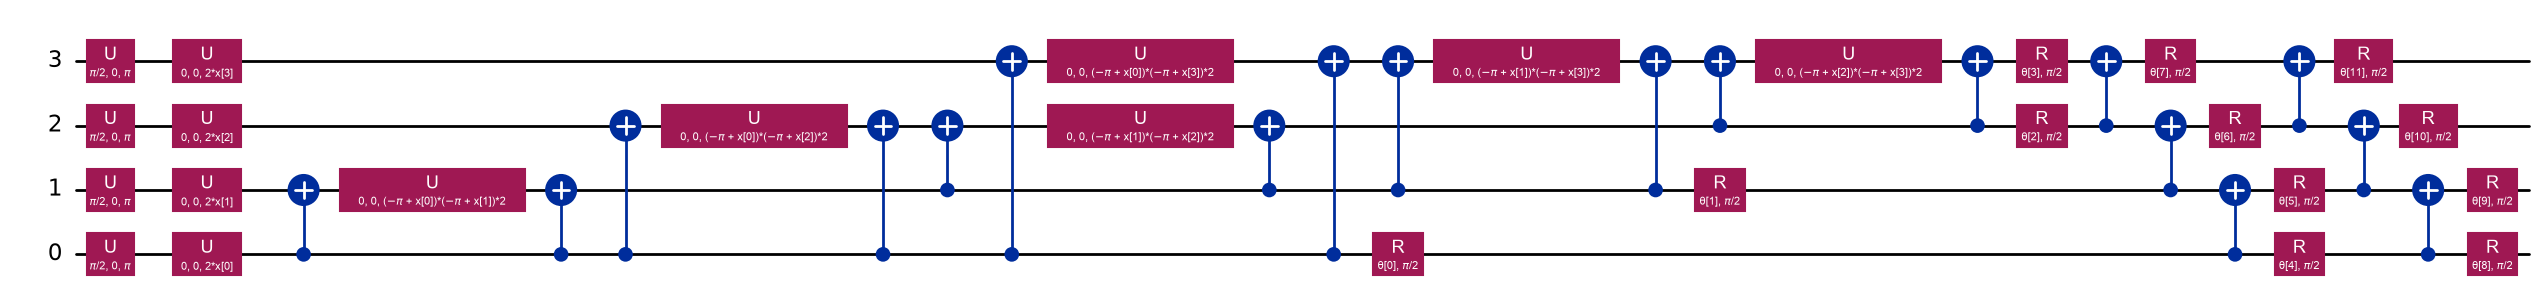

In [ ]:
try:                                  
    from qiskit.circuit.library import zz_feature_map, real_amplitudes
    feature_map = zz_feature_map(feature_dimension=N_QUBITS, reps=FM_REPS)
    ansatz      = real_amplitudes(num_qubits=N_QUBITS, reps=ANSATZ_REPS)
except ImportError:                  
    from qiskit.circuit.library import ZZFeatureMap, RealAmplitudes
    feature_map = ZZFeatureMap(feature_dimension=N_QUBITS, reps=FM_REPS)
    ansatz      = RealAmplitudes(num_qubits=N_QUBITS, reps=ANSATZ_REPS)

print("Feature-map parameters:", feature_map.num_parameters,
      "| Trainable ansatz parameters:", ansatz.num_parameters)
full_circuit = feature_map.compose(ansatz).decompose()
try:
    display(full_circuit.draw("mpl", style="iqp", fold=-1))
except Exception as e:               
    print("(matplotlib drawer unavailable:", type(e).__name__, "- showing text drawing)")
    print(full_circuit.draw("text", fold=120))

## 8. Train the VQC
Training runs on the exact `StatevectorSampler` simulator (CPU). The loss curve is recorded and plotted after training.

Training VQC on 500 samples (4 qubits, 300 iterations)...
Training finished in 5.26 min


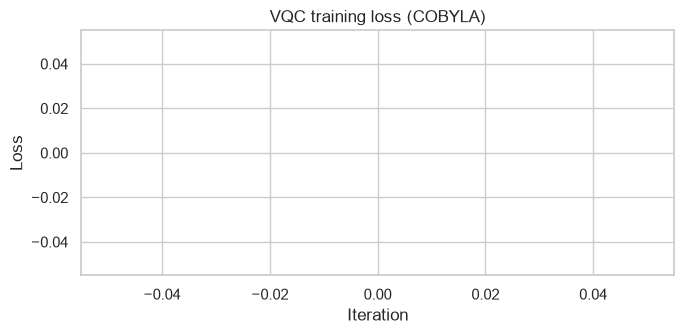

In [8]:
from qiskit.primitives import StatevectorSampler
from qiskit_algorithms.optimizers import COBYLA
from qiskit_machine_learning.algorithms.classifiers import VQC

loss_history = []
def callback(weights, loss):
    loss_history.append(loss)
    if len(loss_history) % 10 == 0:
        print(f"  iteration {len(loss_history):4d} | loss = {loss:.4f}")

vqc = VQC(
    sampler=StatevectorSampler(seed=SEED),
    feature_map=feature_map,
    ansatz=ansatz,
    optimizer=COBYLA(maxiter=MAXITER),
    callback=callback,
    initial_point=np.random.RandomState(SEED).uniform(0, 2*np.pi, ansatz.num_parameters),
)

Xq_train = np.asarray(X_train, dtype=np.float64)
Xq_test  = np.asarray(X_test,  dtype=np.float64)

print(f"Training VQC on {len(y_train)} samples ({N_QUBITS} qubits, {MAXITER} iterations)...")
t0 = time.time()
vqc.fit(Xq_train, y_train)
print(f"Training finished in {(time.time()-t0)/60:.2f} min")

plt.figure(figsize=(7, 3.5))
plt.plot(loss_history); plt.xlabel("Iteration"); plt.ylabel("Loss")
plt.title("VQC training loss (COBYLA)"); plt.tight_layout(); plt.show()

## 9. Evaluate on the held-out test set (natural class distribution)

Inference on 1165 test molecules took 6.0s
VQC train accuracy (balanced train set): 0.588


,Accuracy,Balanced acc,F1 (active),ROC-AUC,PR-AUC
Model,,,,,
LogReg (4 features),0.609,0.638,0.360,0.708,0.306
SVM-RBF (4 features),0.642,0.628,0.353,0.696,0.293
RandomForest (full fingerprint),0.682,0.671,0.399,0.739,0.363
VQC (4 qubits),0.594,0.582,0.309,0.601,0.226


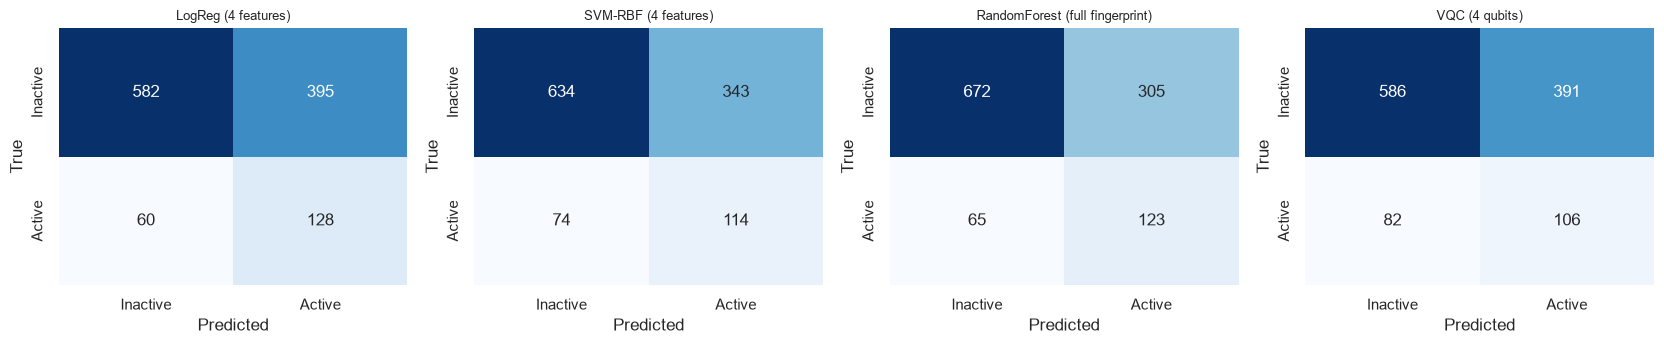

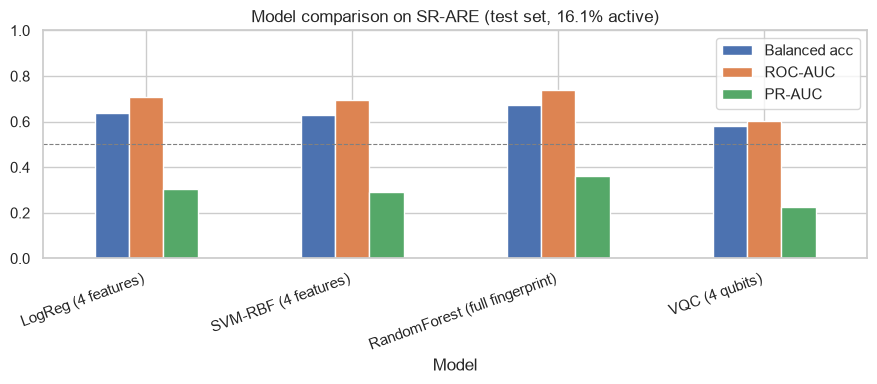

In [9]:
t0 = time.time()
proba_q = vqc.predict_proba(Xq_test)[:, 1]
pred_q  = (proba_q >= 0.5).astype(int)
print(f"Inference on {len(y_test)} test molecules took {time.time()-t0:.1f}s")

train_acc = vqc.score(Xq_train, y_train)
print(f"VQC train accuracy (balanced train set): {train_acc:.3f}")

results.append(evaluate(f"VQC ({N_QUBITS} qubits)", y_test, pred_q, proba_q))
cms[f"VQC ({N_QUBITS} qubits)"] = confusion_matrix(y_test, pred_q)

res = pd.DataFrame(results).set_index("Model").round(3)
display(res)

fig, axes = plt.subplots(1, len(cms), figsize=(4.2 * len(cms), 3.6))
for ax, (name, cm) in zip(axes, cms.items()):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Inactive", "Active"], yticklabels=["Inactive", "Active"])
    ax.set_title(name, fontsize=9); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout(); plt.show()

res[["Balanced acc", "ROC-AUC", "PR-AUC"]].plot(kind="bar", figsize=(9, 4))
plt.axhline(0.5, color="gray", ls="--", lw=0.8); plt.ylim(0, 1); plt.xticks(rotation=20, ha="right")
plt.title(f"Model comparison on {TARGET} (test set, {y_test.mean()*100:.1f}% active)")
plt.tight_layout(); plt.show()

## 10. Save results
Saves the metrics table and the trained circuit weights.

In [10]:
res.to_csv("results_summary.csv")
np.save("vqc_weights.npy", vqc.weights)
print("Saved: results_summary.csv, vqc_weights.npy")

Saved: results_summary.csv, vqc_weights.npy
